In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# ==========================================
# 1. GENERATE DUMMY MULTI-CHANNEL JOURNEYS
# ==========================================
np.random.seed(101)
n_records = 50000

# Generate tracking variables for mock e-commerce sessions
customer_ids = np.random.randint(10000, 18000, size=n_records)
channels = np.random.choice(['Facebook Ads', 'Instagram Ads', 'Google Search', 'Email Marketing', 'Organic'], size=n_records, p=[0.3, 0.3, 0.2, 0.1, 0.1])
timestamps = pd.date_range(start='2026-01-01', end='2026-10-01', periods=n_records)

# Simulate dynamic ad budgets per click across platforms
ad_spend_map = {'Facebook Ads': 15, 'Instagram Ads': 12, 'Google Search': 20, 'Email Marketing': 2, 'Organic': 0}
session_spend = [ad_spend_map[ch] for ch in channels]

# Assemble baseline interactions data frame
marketing_df = pd.DataFrame({
    'CustomerID': customer_ids,
    'Timestamp': timestamps,
    'Channel': channels,
    'Click_Cost': session_spend
})

# Sort sequentially by date parameter to accurately preserve user interaction order
marketing_df.sort_values(by=['CustomerID', 'Timestamp'], inplace=True)
marketing_df.reset_index(drop=True, inplace=True)

# Generate conversion layers: model higher checkouts on final touches like Email or Search
# Establish unique purchase records per conversion event
conversions = marketing_df.groupby('CustomerID').last().reset_index()
conversions['Converted'] = np.random.choice([0, 1], size=len(conversions), p=[0.7, 0.3])
conversions['Order_Value'] = np.where(conversions['Converted'] == 1, np.random.uniform(500, 3500, size=len(conversions)), 0)

# Merge conversion metrics back into the main multi-touch log data framework
conversion_lookup = conversions[['CustomerID', 'Converted', 'Order_Value']]
marketing_df = pd.merge(marketing_df, conversion_lookup, on='CustomerID', how='left')

# Filter the dataset down strictly to paths that resulted in a successful purchase
converted_paths = marketing_df[marketing_df['Converted'] == 1].copy()

print("--- Multi-Touch Click stream Logs Ingested ---")
print(converted_paths.head(10))

--- Multi-Touch Click stream Logs Ingested ---
    CustomerID                     Timestamp          Channel  Click_Cost  \
14       10002 2026-01-12 18:55:15.666313326    Instagram Ads          12   
15       10002 2026-03-02 12:52:10.334606692          Organic           0   
16       10002 2026-03-07 10:48:28.426168523    Google Search          20   
17       10002 2026-03-24 10:05:18.102362047          Organic           0   
18       10002 2026-04-13 18:52:38.415168303    Google Search          20   
19       10002 2026-04-18 05:09:10.451009020    Google Search          20   
20       10002 2026-06-18 00:58:03.717674352     Facebook Ads          15   
21       10002 2026-07-09 01:28:54.442688854  Email Marketing           2   
22       10003 2026-01-13 21:39:13.367067341    Instagram Ads          12   
23       10003 2026-06-13 18:21:40.778015560     Facebook Ads          15   

    Converted  Order_Value  
14          1   989.657162  
15          1   989.657162  
16          1   98

In [9]:
# ==========================================
# 2. COMPUTE ATTRIBUTION VECTOR LAYERS
# ==========================================
print("\n--- Running Attribution Engine Processing ---")

# A. First-Touch Attribution Models (The awareness driver)
first_touch = converted_paths.groupby('CustomerID').first().reset_index()
first_touch_rev = first_touch.groupby('Channel')['Order_Value'].sum().reset_index().rename(columns={'Order_Value': 'First_Touch_Revenue'})

# B. Last-Touch Attribution Models (The conversion closer)
last_touch = converted_paths.groupby('CustomerID').last().reset_index()
last_touch_rev = last_touch.groupby('Channel')['Order_Value'].sum().reset_index().rename(columns={'Order_Value': 'Last_Touch_Revenue'})


--- Running Attribution Engine Processing ---


In [10]:
# ==========================================
# 3. CALCULATE CHANNEL LEVEL ECONOMICS (CAC & ROAS)
# ==========================================
# Calculate absolute marketing budget deployment metrics across the environment
channel_spend = marketing_df.groupby('Channel')['Click_Cost'].sum().reset_index().rename(columns={'Click_Cost': 'Total_Ad_Spend'})
conversions_count = last_touch.groupby('Channel')['Converted'].sum().reset_index().rename(columns={'Converted': 'Total_Conversions'})

# Merge operational datasets into a consolidated financial matrix data frame
matrix_summary = pd.merge(channel_spend, conversions_count, on='Channel')
matrix_summary = pd.merge(matrix_summary, first_touch_rev, on='Channel')
matrix_summary = pd.merge(matrix_summary, last_touch_rev, on='Channel')

# Calculate foundational unit economics indices
matrix_summary['CAC'] = matrix_summary['Total_Ad_Spend'] / matrix_summary['Total_Conversions']
matrix_summary['Last_Touch_ROAS'] = matrix_summary['Last_Touch_Revenue'] / matrix_summary['Total_Ad_Spend']

print("\n--- Calculated Strategic Marketing Matrix ---")
print(matrix_summary[['Channel', 'Total_Ad_Spend', 'CAC', 'Last_Touch_ROAS']])


--- Calculated Strategic Marketing Matrix ---
           Channel  Total_Ad_Spend         CAC  Last_Touch_ROAS
0  Email Marketing           10262   41.048000        48.334951
1     Facebook Ads          222855  300.343666         6.622917
2    Google Search          202140  413.374233         4.708567
3    Instagram Ads          179568  255.431010         7.907792
4          Organic               0    0.000000              inf



Exported operational data array: 'Marketing_Attribution_Matrix.csv'


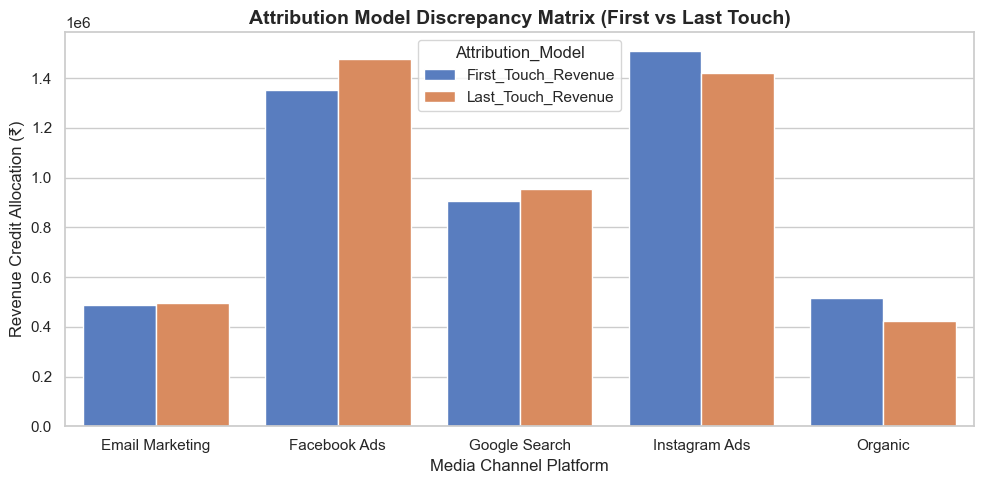

In [11]:
# ==========================================
# 4. EXPORT VISUAL STRUCTURES (POWER BI DEPLOYMENT)
# ==========================================
matrix_summary.to_csv(r"C:\Users\ashut\Downloads\campaign_dataset.csv", index=False)
print("\nExported operational data array: 'Marketing_Attribution_Matrix.csv'")

# Generate quick visual validation chart
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
melted_rev = pd.melt(matrix_summary, id_vars=['Channel'], value_vars=['First_Touch_Revenue', 'Last_Touch_Revenue'], var_name='Attribution_Model', value_name='Attributed_Revenue')
sns.barplot(data=melted_rev, x='Channel', y='Attributed_Revenue', hue='Attribution_Model', palette='muted')
plt.title('Attribution Model Discrepancy Matrix (First vs Last Touch)', fontsize=14, fontweight='bold')
plt.xlabel('Media Channel Platform')
plt.ylabel('Revenue Credit Allocation (₹)')
plt.tight_layout()
plt.savefig('attribution_discrepancy_plot.png', dpi=300)
plt.show()
